# F.E. Walter: run a five-year operation comparison

## Goal

Calculate reservoir inflow from weather, operate the reservoir with the Hanasaki
rule, and compare water elevation and downstream flow with observations.
The operation period is **2021–2025 (1,826 days)**.

Run the cells in order: **settings → hydrology → operation → checks → figures**.
Verified tables and figures from the completed run are included below.
Rerun the cells to calculate your own results in a fresh output folder.
All computation is local. LLM settings are introduced at the end for a later comparison.

## Setup

Complete [installation](../docs/GETTING_STARTED.md), open this notebook in Jupyter,
and select that Python environment. The weather, calibrated model, observations,
and reservoir settings are included in the repository.

In [1]:
from pathlib import Path
import os, sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/llm_reservoir_agent").is_dir())
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Code
from llm_reservoir_agent.coupled import prepare_coupled, prepared_experiment
from llm_reservoir_agent.workflow import load_settings, run_settings
from llm_reservoir_agent.verification import verify_run
from examples.fe_walter.operation.execution import create_simulation
from examples.fe_walter.operation.figures import plot_run
from examples.fe_walter.operation.preflight import check_preparation

case_folder = ROOT / "examples/fe_walter/operation"
experiment_file = case_folder / "experiment.yaml"

## 1. Read the experiment

[experiment.yaml](../examples/fe_walter/operation/experiment.yaml) selects the
operation dates, shared [physical case](../examples/fe_walter/operation/case.json),
and [Rule-based agent](../examples/fe_walter/operation/agents.rule.yaml).
Its prepared entry can use saved inflows. Here, `create_simulation` connects
those same settings to weather inputs so you calculate inflows yourself.
Each execution uses a new folder under `runs/`; earlier results are preserved.

In [2]:
Code(experiment_file.read_text(encoding="utf-8"), language="yaml")

# Prepared daily operation: read frozen inflows; no hydrology is recomputed.
schema_version: llm-reservoir-experiment.v2     # Settings format, separate from package version.
run_id: fe-walter-2021-2025-rule                # Unique label for this method.
case: case.json                                 # Shared reservoir and downstream network.
output: ../../../runs/fe-walter-2021-2025-rule  # New directory when eventually run.
start_date: '2021-01-01'                        # First daily decision (included).
end_date: '2025-12-31'                          # Last daily decision (included); 1826 days.
max_calls: 0                                    # 0 for rules; null leaves per-decision retry limits in force.
agents:
  file: agents.rule.yaml
auditors:
  file: ../coupled/auditors.yaml
extensions:
  seeded_hanasaki: __init__.py

| Setting | What it controls |
|---|---|
| `schema_version` | Configuration format accepted by the loader. |
| `run_id`, `output` | Run label and output directory. The lesson creates a fresh directory. |
| `case` | Reservoir limits, initial storage, and downstream connections. |
| `start_date`, `end_date` | First and last daily decisions, both included. |
| `agents.file` | File assigning a decision method to the reservoir. |
| `max_calls: 0` | Rule-based operation makes no LLM requests. |

Check that all three methods share physical inputs. The complete
[preparation record](../examples/fe_walter/operation/provenance.json) and
[C&V reference](../examples/fe_walter/downstream/validation.md) provide the details.

In [3]:
preparation = check_preparation()
pd.DataFrame([
    {"Method": label, "Days": item["days"], "LLM executed here": False}
    for label, item in zip(
        ["Rule-based", "LLM without additional operating knowledge",
         "LLM with additional operating knowledge"], preparation["methods"], strict=True)
])

,Method,Days,LLM executed here
0,Rule-based,1826,False
1,LLM without additional operating knowledge,1826,False
2,LLM with additional operating knowledge,1826,False


## 2. Calculate daily inflows

[hydrology.yaml](../examples/fe_walter/operation/hydrology/hydrology.yaml) connects
the accepted [model](../examples/fe_walter/operation/hydrology/model.yaml) and
[weather table](../examples/fe_walter/operation/hydrology/forcing.csv.gz):
precipitation (mm/day), temperature (°C), and Hamon PET (cm/day).
HydroCNHS calculates runoff and routes it to three separate boundaries:
reservoir inflow, local inflow above White Haven, and local inflow above Lehighton.

Hydrology starts in 1989 to retain the accepted warm-up and historical state;
only 2021–2025 inflows enter the reservoir experiment. The native progress bar
counts **13,514 hydrology days**, after runoff and routing setup.
Setup can take some time before the bar begins.

In [4]:
Code((case_folder / "hydrology/hydrology.yaml").read_text(encoding="utf-8"), language="yaml")

model: model.yaml
forcing: forcing.csv.gz
zero_flow_nodes:
- __AGGREGATION_OUTLET__
- __LATERAL_OUTLET__
- WHITE_HAVEN
- LEHIGHTON
- __PREPARATION_COLLECTOR__
inflow_bindings:
  FEW_INFLOW:
    routed: __AGGREGATION_OUTLET__
  USGS01447800:
    routed: __LATERAL_OUTLET__
  USGS01449000:
    routed: LEHIGHTON

In [5]:
# Create a separate workspace for this execution.
simulation = create_simulation(
    experiment_file, output=os.environ.get("HYDROREOPLLM_TUTORIAL_OUTPUT")
)
print("Output folder:", simulation.path.parent)
print("Calculating runoff and routing from weather…")
prepare_coupled(simulation, progress=True)
print("Daily inflows are ready for reservoir operation.")

Output folder: C:\Users\wenyu\Documents\LLM Rervoir\_qa\hydroops-delivery-20261017\executable-tutorial-20261021T1502Z\actual-run-corrected
Calculating runoff and routing from weather…

Daily inflows are ready for reservoir operation.


HydroOpsWeather: 100%|██████████| 13514/13514 [00:03<00:00, 4130.45it/s]


## 3. Operate the reservoir and route its outflow

The [agent file](../examples/fe_walter/operation/agents.rule.yaml) selects the
Hanasaki comparator with `alpha: 0.85`. All methods start from the same physical
storage. The [initialization file](../examples/fe_walter/operation/initialization.json)
also supplies the Rule-based annual coefficient from the previous operating year.

Each day, the rule requests a release. The engine applies reservoir limits,
computes spill, and routes total outflow downstream together with local inflows.
The next progress bar counts **1,826 operation days**.

In [6]:
Code((case_folder / "agents.rule.yaml").read_text(encoding="utf-8"), language="yaml")

# Case adapter supplies the accepted prior operating-year coefficient.
fe_operator:                                   # Independent decision history.
  reservoir_id: FEWalter                       # Reservoir ID in case.json.
  type: rule_based                             # Deterministic Hanasaki rule.
  rule: seeded_hanasaki                        # Case adapter registered in experiment.yaml.
  rule_parameters:
    purpose: flood_control                     # Generic non-irrigation operating purpose.
    alpha: 0.85                                # Published generic comparator; fixed before evaluation.
    inflow_statistics_file: ../../../data/benchmark/fe_walter_statistics.json
    initialization_file: initialization.json   # Prior coefficient plus common physical start (m3).
  auditors: [release_limits]                   # Audit requested release; preserve failures.

In [7]:
operation_settings = load_settings(prepared_experiment(simulation), runtime_root=ROOT)
records, result = run_settings(operation_settings, progress=True, runtime_root=ROOT)
summary = result["summary"]
run_output = Path(operation_settings.report["output"])
print("Completed reservoir days:", summary["completed_reservoir_days"])
print("LLM requests:", summary["observed_network_calls"])


Completed reservoir days: {'fe_walter': 1826}
LLM requests: 0


100%|██████████| 1826/1826 [00:44<00:00, 40.84it/s]


## 4. Check the completed run

Verification checks recorded decisions, reservoir water balance, and downstream
routing. A completed run can still differ from observations: Hanasaki is a
generic comparator. Seasonal operating performance is assessed separately.

In [8]:
verification = verify_run(run_output, require_offline=True)
if summary["observed_network_calls"] != 0:
    raise RuntimeError("Unexpected model request")
pd.DataFrame([
    {"Check": "Reservoir water balance", "Maximum residual (m³)": summary["max_mass_balance_residual_m3"]},
    {"Check": "Whole network water balance", "Maximum residual (m³)": summary["max_system_balance_residual_m3"]},
])

,Check,Maximum residual (m³)
0,Reservoir water balance,2.980232e-08
1,Whole network water balance,7.757917e-07


## 5. Plot this run

`plot_run` reads the CSVs just written to `run_output` and joins their simulated
values to retained observations. It draws new figures and exports PDF, SVG,
PNG, and daily CSV files under this run's `figures/` folder.

The upper panel shows end-of-day elevation. The lower panel shows daily controlled
release, upstream simulated inflow, and spill separately, all in cfs.

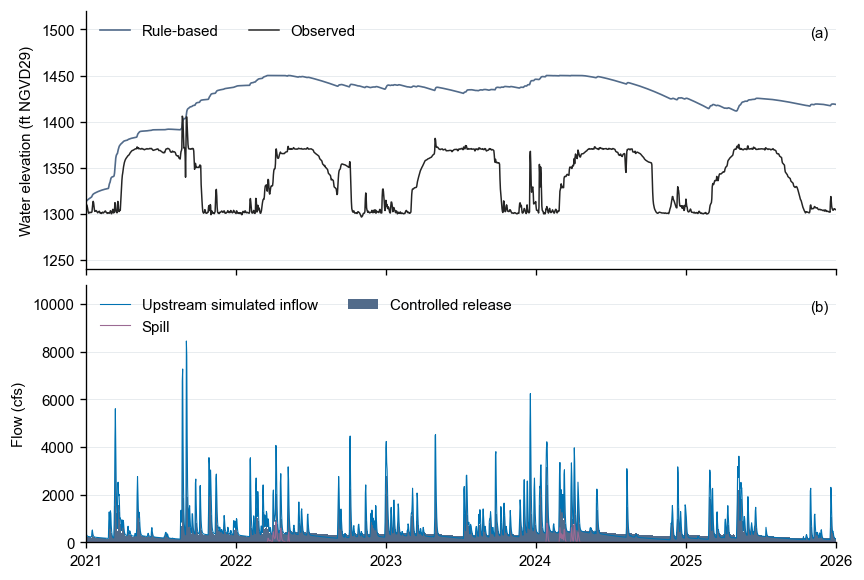

In [9]:
reservoir_figure, downstream_figure = plot_run(run_output, export=True)
# Show each figure once, in its own cell.
plt.close(reservoir_figure)
plt.close(downstream_figure)
reservoir_figure

Daily mean streamflow is compared at **White Haven (USGS 01447800)** and
**Lehighton (USGS 01449000)**. The first 21 routing days and White Haven provisional
records are excluded from primary scores; all dates remain visible in the figures.

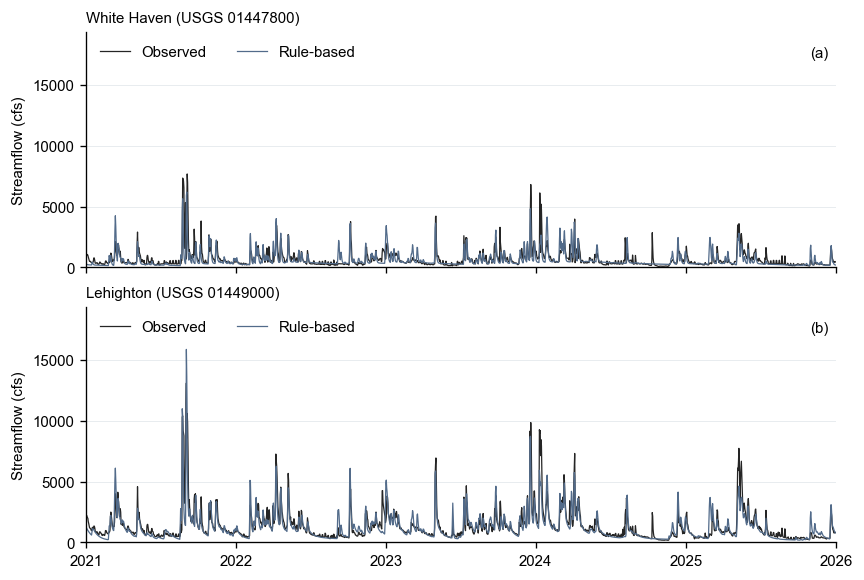

In [10]:
downstream_figure

## 6. Prepare a later LLM comparison

Keep the same physical case, initial storage, and newly prepared inflows. Select
[llm_available.yaml](../examples/fe_walter/operation/llm_available.yaml) for
**LLM without additional operating knowledge**, or
[llm_knowledge.yaml](../examples/fe_walter/operation/llm_knowledge.yaml) for
**LLM with additional operating knowledge**. These entries link model settings,
prompts, and optional knowledge. This notebook executes the Rule-based method only.

These terminal commands show how to check and start the LLM entry. Run the second
command separately when you intend to begin the full experiment:

```shell
reservoir-experiment check examples/fe_walter/operation/llm_available.yaml
reservoir-experiment run examples/fe_walter/operation/llm_available.yaml --allow-network
```

The 2021–2025 LLM results have not been generated. The
[saved three-method illustration](../examples/fe_walter/results.md) covers **2016**
with the earlier prompt; its figures can be read directly without executing an LLM.

## Next steps

Inspect your two figures and daily CSVs. The
[case results page](../examples/fe_walter/operation/README.md) explains the retained
reference run. The [agent guide](../docs/LLM_MODULES.md) describes how to
customize the information supplied to an LLM.